In [1]:
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams
import nltk
nltk.download('punkt')

print(" Langkah 1 selesai — Library siap!")

 Langkah 1 selesai — Library siap!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [3]:
# Baca dataset
df = pd.read_csv('news_data.csv')

# Lihat nama kolom yang tersedia
print("Kolom yang tersedia:", df.columns.tolist())

Kolom yang tersedia: ['title', 'author', 'publish_date', 'article_text', 'url', 'main_image', 'tag']


In [ ]:
# Ganti 'nama_kolom_teks_kamu' dengan nama yang benar dari langkah 2
text_column = 'article_text'  # Ganti dengan nama kolom teks yang sesuai

# Hapus nilai kosong
df = df.dropna(subset=[text_column])

print(f"Jumlah dokumen: {len(df)}")

 Jumlah dokumen: 19812


In [6]:
# Gabungkan semua teks
all_text = " ".join(df[text_column].astype(str)).lower()
tokens = all_text.split()

print(f" Total token: {len(tokens):,}")
print(f"Contoh token pertama: {tokens[:15]}")

 Total token: 6,400,675
Contoh token pertama: ['sekjen', 'pdip', 'sekaligus', 'sekretaris', 'tim', 'pemenang', 'nasional', '(tpn)', 'ganjar', 'pranowo-mahfud', 'md,', 'hasto', 'kristiyanto,', 'ingin', 'debat']


In [7]:
unigram = Counter(tokens)

print("=== 20 Kata Paling Sering Muncul ===")
for kata, jumlah in unigram.most_common(20):
    print(f"{kata:<20} : {jumlah:,} kali")

=== 20 Kata Paling Sering Muncul ===
yang                 : 139,226 kali
dan                  : 112,424 kali
di                   : 110,609 kali
dengan               : 55,657 kali
itu                  : 53,001 kali
untuk                : 52,906 kali
ini                  : 46,076 kali
dalam                : 45,140 kali
dari                 : 40,754 kali
akan                 : 40,158 kali
juga                 : 37,725 kali
tidak                : 37,228 kali
ada                  : 34,627 kali
partai               : 33,359 kali
kita                 : 30,559 kali
kata                 : 29,766 kali
prabowo              : 29,357 kali
ke                   : 28,143 kali
ganjar               : 27,382 kali
sebagai              : 26,005 kali


In [8]:
total_token = sum(unigram.values())

unigram_prob = {
    kata: jumlah / total_token
    for kata, jumlah in unigram.items()
}

print("\n=== 10 Kata dengan Probabilitas Tertinggi ===")
urut_prob = sorted(unigram_prob.items(), key=lambda x: x[1], reverse=True)
for kata, prob in urut_prob[:10]:
    print(f"{kata:<20} : {prob:.6f}")


=== 10 Kata dengan Probabilitas Tertinggi ===
yang                 : 0.021752
dan                  : 0.017564
di                   : 0.017281
dengan               : 0.008695
itu                  : 0.008281
untuk                : 0.008266
ini                  : 0.007199
dalam                : 0.007052
dari                 : 0.006367
akan                 : 0.006274


In [9]:
bigram_list = list(bigrams(tokens))
bigram_count = Counter(bigram_list)

print("=== 20 Bigram Paling Sering Muncul ===")
for pasangan, jumlah in bigram_count.most_common(20):
    print(f"{pasangan[0]} {pasangan[1]:<25} : {jumlah:,}")

=== 20 Bigram Paling Sering Muncul ===
advertisement scroll                    : 19,450
scroll to                        : 19,450
to continue                  : 19,450
continue with                      : 19,450
with content                   : 19,450
[gambas:video 20detik]                  : 8,757
cak imin                      : 7,599
ketua umum                      : 7,325
ganjar pranowo                   : 7,111
prabowo subianto                  : 6,179
anies baswedan                  : 6,141
calon presiden                  : 5,795
yang akan                      : 5,037
salah satu                      : 4,811
saat ini                       : 4,740
pilpres 2024.                     : 4,503
gibran rakabuming                : 4,090
pemilu 2024.                     : 3,968
hal itu                       : 3,890
tidak ada                       : 3,810


In [10]:
trigram_list = list(trigrams(tokens))
trigram_count = Counter(trigram_list)

print("=== 20 Trigram Paling Sering Muncul ===")
for tiga_kata, jumlah in trigram_count.most_common(20):
    print(f"{' '.join(tiga_kata):<35} : {jumlah:,}")

=== 20 Trigram Paling Sering Muncul ===
advertisement scroll to             : 19,450
scroll to continue                  : 19,450
to continue with                    : 19,450
continue with content               : 19,450
presiden joko widodo                : 3,431
gibran rakabuming raka              : 2,504
calon wakil presiden                : 2,268
di pilpres 2024.                    : 2,232
joko widodo (jokowi)                : 2,204
ketua umum partai                   : 2,149
bakal calon presiden                : 1,933
capres dan cawapres                 : 1,617
kepada wartawan di                  : 1,584
halaman 1 2                         : 1,519
wali kota solo                      : 1,471
koalisi indonesia maju              : 1,405
1 2 selanjutnya                     : 1,393
iskandar atau cak                   : 1,368
muhaimin iskandar atau              : 1,306
presiden dan wakil                  : 1,246


In [11]:
def prob_bigram(kata1, kata2):
    pembilang = bigram_count.get((kata1, kata2), 0)
    penyebut = unigram.get(kata1, 0)
    if penyebut == 0:
        return 0.0
    return pembilang / penyebut

# Coba beberapa contoh
uji_bigram = [
    ("berita", "indonesia"),
    ("presiden", "jokowi"),
    ("di", "jakarta"),
    ("yang", "penting"),
    ("saya", "belajar")
]

print("=== Probabilitas Bigram ===")
for k1, k2 in uji_bigram:
    p = prob_bigram(k1, k2)
    print(f"P({k2} | {k1}) = {p:.6f}")

=== Probabilitas Bigram ===
P(indonesia | berita) = 0.000000
P(jokowi | presiden) = 0.070179
P(jakarta | di) = 0.007938
P(penting | yang) = 0.004712
P(belajar | saya) = 0.000638


In [12]:
def prob_kalimat(kalimat):
    kata = kalimat.lower().split()
    if len(kata) < 2:
        return unigram_prob.get(kata[0], 0.0)
    hasil = 1.0
    for i in range(len(kata) - 1):
        hasil *= prob_bigram(kata[i], kata[i+1])
    return hasil

# Uji 5 kalimat
kalimat_uji = [
    "berita terbaru hari ini",
    "presiden memberikan sambutan",
    "ekonomi indonesia terus tumbuh",
    "cuaca di jakarta cerah",
    "saya sedang belajar nlp"
]

print("=== Probabilitas Kalimat ===")
for k in kalimat_uji:
    p = prob_kalimat(k)
    print(f"P('{k}') = {p:.8f}")

=== Probabilitas Kalimat ===
P('berita terbaru hari ini') = 0.00000000
P('presiden memberikan sambutan') = 0.00000615
P('ekonomi indonesia terus tumbuh') = 0.00000017
P('cuaca di jakarta cerah') = 0.00000000
P('saya sedang belajar nlp') = 0.00000000


In [13]:
jumlah_vocab = len(unigram)

def prob_bigram_smoothed(kata1, kata2):
    pembilang = bigram_count.get((kata1, kata2), 0) + 1
    penyebut = unigram.get(kata1, 0) + jumlah_vocab
    return pembilang / penyebut

# Coba yang sebelumnya mungkin 0
uji_smoothing = [
    ("belajar", "nlp"),
    ("kecerdasan", "buatan"),
    ("data", "sains")
]

print("=== Probabilitas dengan Smoothing ===")
for k1, k2 in uji_smoothing:
    p_asli = prob_bigram(k1, k2)
    p_smooth = prob_bigram_smoothed(k1, k2)
    print(f"P({k2} | {k1}) = asli: {p_asli:.8f} → smoothed: {p_smooth:.8f}")

=== Probabilitas dengan Smoothing ===
P(nlp | belajar) = asli: 0.00000000 → smoothed: 0.00000645
P(buatan | kecerdasan) = asli: 0.38805970 → smoothed: 0.00017449
P(sains | data) = asli: 0.00048876 → smoothed: 0.00001276


In [14]:
def prediksi_kata(kata_depan, jumlah=5):
    kandidat = []
    for (k1, k2), hitung in bigram_count.items():
        if k1 == kata_depan:
            p = prob_bigram_smoothed(k1, k2)
            kandidat.append((k2, p))
    kandidat.sort(key=lambda x: x[1], reverse=True)
    return kandidat[:jumlah]

# Prediksi untuk 5 kata
kata_kunci = ["di", "yang", "berita", "presiden", "indonesia"]

print("=== PREDIKSI KATA BERIKUTNYA ===")
for kata in kata_kunci:
    hasil = prediksi_kata(kata)
    print(f"\nSetelah '{kata}':")
    for k_next, prob in hasil:
        print(f"  → {k_next:<15} {prob:.6f}")

=== PREDIKSI KATA BERIKUTNYA ===

Setelah 'di':
  → pilpres         0.014200
  → kantor          0.007023
  → jawa            0.006612
  → pemilu          0.006431
  → dalam           0.006314

Setelah 'yang':
  → akan            0.017142
  → sudah           0.009769
  → tidak           0.009088
  → telah           0.007247
  → ada             0.006247

Setelah 'berita':
  → selengkapnya    0.001175
  → lengkapnya      0.000770
  → yang            0.000629
  → bohong          0.000507
  → hoax            0.000359

Setelah 'presiden':
  → joko            0.020771
  → dan             0.012142
  → jokowi          0.009280
  → (capres)        0.005532
  → yang            0.004921

Setelah 'indonesia':
  → maju            0.009831
  → yang            0.007284
  → raya            0.003077
  → di              0.002308
  → maju.           0.001917


In [15]:
def perplexity(prob_kalimat, jumlah_kata):
    if prob_kalimat == 0 or jumlah_kata == 0:
        return float("inf")
    return prob_kalimat ** (-1 / jumlah_kata)

print("=== PERHITUNGAN PERPLEXITY ===")
for k in kalimat_uji:
    kata = k.split()
    N = len(kata)
    p = prob_kalimat(k)
    pp = perplexity(p, N)
    print(f"Kalimat: '{k}'")
    print(f"  Jumlah kata: {N} | Probabilitas: {p:.8f} | Perplexity: {pp:.4f}")
    print()

=== PERHITUNGAN PERPLEXITY ===
Kalimat: 'berita terbaru hari ini'
  Jumlah kata: 4 | Probabilitas: 0.00000000 | Perplexity: inf

Kalimat: 'presiden memberikan sambutan'
  Jumlah kata: 3 | Probabilitas: 0.00000615 | Perplexity: 54.5698

Kalimat: 'ekonomi indonesia terus tumbuh'
  Jumlah kata: 4 | Probabilitas: 0.00000017 | Perplexity: 49.2733

Kalimat: 'cuaca di jakarta cerah'
  Jumlah kata: 4 | Probabilitas: 0.00000000 | Perplexity: inf

Kalimat: 'saya sedang belajar nlp'
  Jumlah kata: 4 | Probabilitas: 0.00000000 | Perplexity: inf



In [16]:
print("=" * 60)
print("RINGKASAN DATA & MODEL N-GRAM")
print("=" * 60)
print(f"Total token dalam corpus  : {len(tokens):,}")
print(f"Jumlah kata unik (vocab)   : {len(unigram):,}")
print(f"Jumlah bigram unik         : {len(bigram_count):,}")
print(f"Jumlah trigram unik        : {len(trigram_count):,}")
print()
print("""+-----------+----------------+----------------+----------------+
|  Model    |  Konteks       |  Kelebihan     |  Kekurangan    |
+-----------+----------------+----------------+----------------+
| Unigram   |  1 kata        |  Cepat &       |  Tidak paham   |
|           |  saja          |  sederhana     |  konteks       |
+-----------+----------------+----------------+----------------+
| Bigram    |  2 kata        |  Lebih         |  Konteks       |
|           |  berturut-turut|  kontekstual   |  masih pendek  |
+-----------+----------------+----------------+----------------+
| Trigram   |  3 kata        |  Konteks       |  Banyak data   |
|           |  berturut-turut|  lebih panjang |  dibutuhkan    |
+-----------+----------------+----------------+----------------+""")
print()
print("Masalah Utama: Sparsity — semakin besar N, semakin banyak kombinasi kata yang belum pernah muncul dalam data → probabilitas nol")
print("Solusi: Laplace Smoothing — menambahkan 1 ke setiap hitungan agar tidak ada yang bernilai 0")

RINGKASAN DATA & MODEL N-GRAM
Total token dalam corpus  : 6,400,675
Jumlah kata unik (vocab)   : 154,672
Jumlah bigram unik         : 1,604,172
Jumlah trigram unik        : 3,464,627

+-----------+----------------+----------------+----------------+
|  Model    |  Konteks       |  Kelebihan     |  Kekurangan    |
+-----------+----------------+----------------+----------------+
| Unigram   |  1 kata        |  Cepat &       |  Tidak paham   |
|           |  saja          |  sederhana     |  konteks       |
+-----------+----------------+----------------+----------------+
| Bigram    |  2 kata        |  Lebih         |  Konteks       |
|           |  berturut-turut|  kontekstual   |  masih pendek  |
+-----------+----------------+----------------+----------------+
| Trigram   |  3 kata        |  Konteks       |  Banyak data   |
|           |  berturut-turut|  lebih panjang |  dibutuhkan    |
+-----------+----------------+----------------+----------------+

Masalah Utama: Sparsity — semakin b

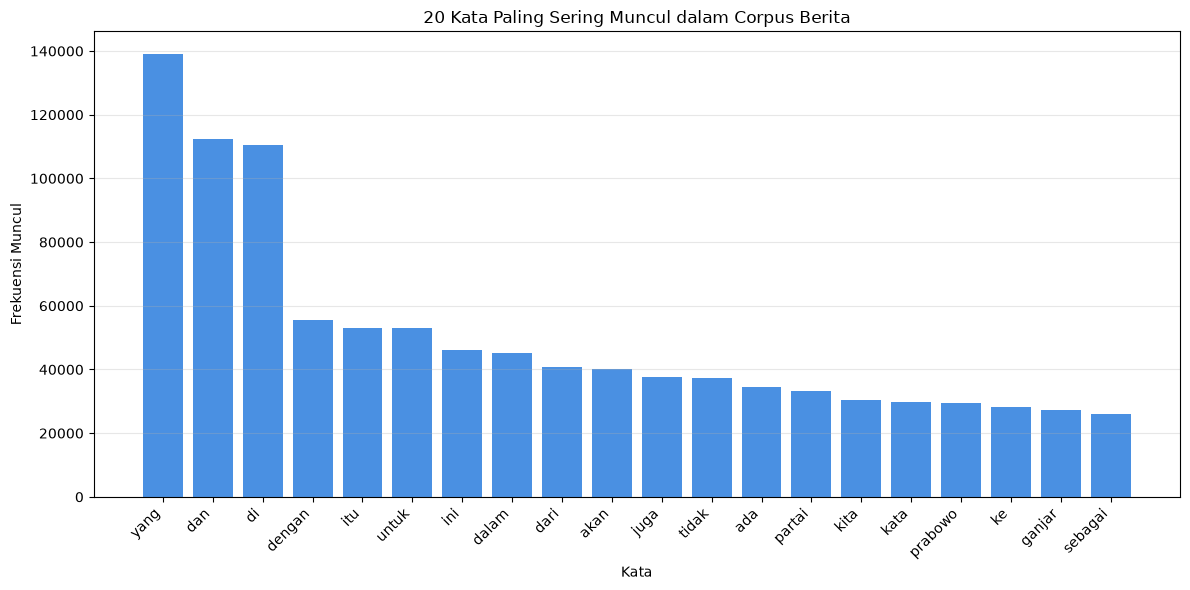

In [17]:
import matplotlib.pyplot as plt

top20 = unigram.most_common(20)
kata_list = [item[0] for item in top20]
jumlah_list = [item[1] for item in top20]

plt.figure(figsize=(12, 6))
plt.bar(kata_list, jumlah_list, color="#4A90E2")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi Muncul")
plt.title("20 Kata Paling Sering Muncul dalam Corpus Berita")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()